## 在deepseek api平台申请API，拿到API-key；然后交一点钱，很便宜的。

In [ ]:
# https://platform.deepseek.com/transactions

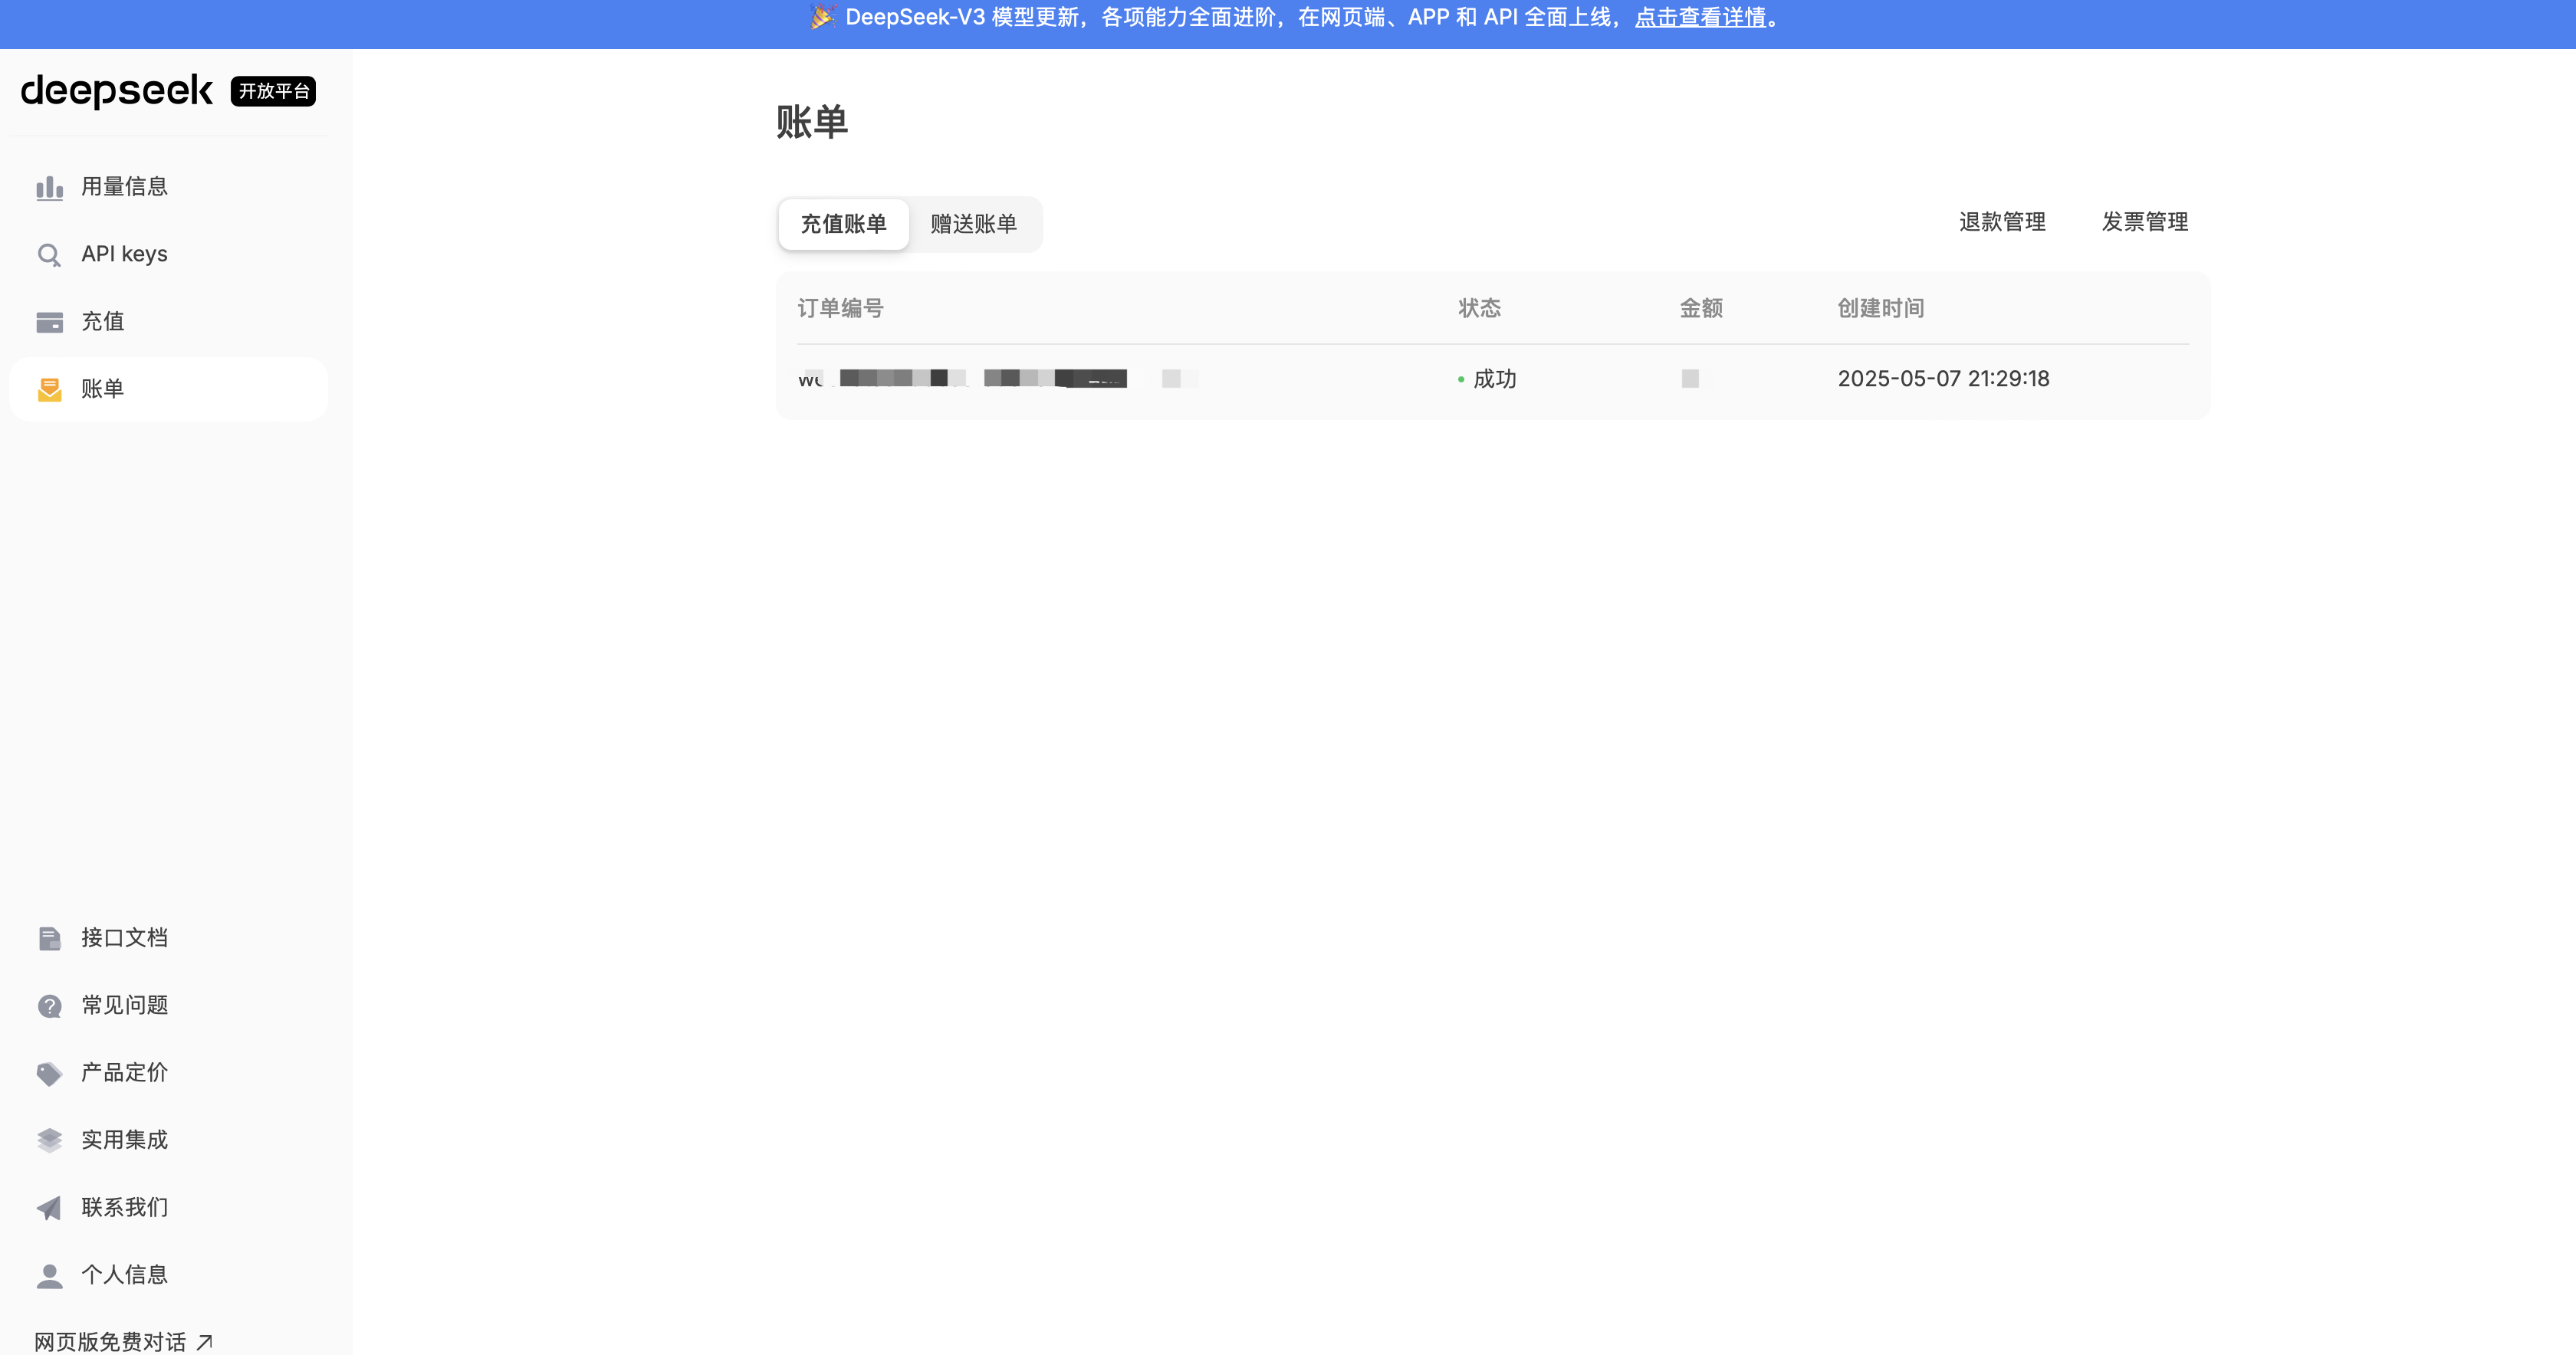

In [ ]:
import requests
import json

# 定义DeepSeek API的URL和headers
DEEPSEEK_API_URL = "https://api.deepseek.com/v1/chat/completions"
API_KEY = "yourkey"  #直接复制过来

In [ ]:
# 准备prompt和论文文本
paper_text = """
随着肿瘤免疫微环境（Tumor Immune Microenvironment, TIME）研究的深入，
T细胞耗竭（T cell exhaustion）被认为是限制免疫治疗效果的关键机制之一。
本研究基于免疫编辑理论，提出了一种基于单细胞RNA测序（scRNA-seq）的T细胞状态动态识别方法。
具体而言，我们使用Seurat与Monocle3等生物信息学工具对50例非小细胞肺癌患者的肿瘤样本进行细胞亚群聚类和轨迹分析，
结合pseudotime推断T细胞从激活到耗竭的转化过程。此外，借助CellChat软件构建细胞间通讯网络，
进一步识别可能诱导T细胞耗竭的免疫抑制信号通路，如PD-1/PD-L1和TGF-β路径。研究结果揭示了T细胞功能衰竭的关键节点，并为个体化免疫治疗提供了潜在靶点。
"""

prompt = f"""
请从以下科技论文文本中提取包含理论、方法、工具的实体或专业术语，以json字典的格式输出:

{paper_text}
"""

In [ ]:
# 准备请求数据
data = {
    "model": "deepseek-chat",
    "messages": [
        {"role": "user", "content": prompt}
    ],
    "temperature": 0.3
}

headers = {
    "Content-Type": "application/json",
    "Authorization": f"Bearer {API_KEY}"  
}

# 发送请求
response = requests.post(DEEPSEEK_API_URL, headers=headers, data=json.dumps(data))

In [4]:
# 处理响应
if response.status_code == 200:
    result = response.json()
    try:
        entities = result['choices'][0]['message']['content']
        print("提取到的实体和专业术语:")
        print(entities)
    except KeyError:
        print("无法解析API响应，原始响应:")
        print(result)
else:
    print(f"请求失败，状态码: {response.status_code}")
    print(response.text)


提取到的实体和专业术语:
```json
{
  "理论": [
    "肿瘤免疫微环境",
    "T细胞耗竭",
    "免疫编辑理论"
  ],
  "方法": [
    "单细胞RNA测序",
    "细胞亚群聚类",
    "轨迹分析",
    "pseudotime推断",
    "细胞间通讯网络构建"
  ],
  "工具": [
    "Seurat",
    "Monocle3",
    "CellChat"
  ],
  "专业术语": [
    "TIME",
    "scRNA-seq",
    "非小细胞肺癌",
    "PD-1/PD-L1",
    "TGF-β路径",
    "免疫治疗",
    "免疫抑制信号通路",
    "个体化免疫治疗"
  ]
}
```


## 提问：
+ 1，使用deepseek开展工作的感觉如何？
+ 2，你觉得大语言模型的活干的怎么样？
+ 3，还是那个问题，如果可以抽取实体，那么如何识别关系呢？你试试用大语言模型识别下关系？

### 课堂提问的思考（一）：使用体验与效果评价

#### 1. 使用 DeepSeek 开展工作的感觉如何？

- **门槛很低**：整个流程就是"申请 key → 拼 prompt → requests.post → 取 `choices[0].message.content`"，二十几行代码，不涉及任何模型训练和标注数据，对零基础同学非常友好。
- **成本极低**：这类抽取任务的 token 消耗很小（几百 token 级别），调用一次的费用可以忽略，适合反复试错、调整提示词。
- **迭代很快**：想改抽取口径，只要改 prompt 里的一句话，不用重新标注数据、不用重新训练。这是它相比传统 NER 模型最大的优势。
- **需要注意的地方**：结果不是 100% 可复现（即使 `temperature=0.3` 也会有小幅波动）；输出格式需要约束，否则模型可能夹带解释性文字导致 `json.loads` 失败；涉及数据保密时不能把原文直接发到外部 API。

#### 2. 你觉得大语言模型干得怎么样？

**优点明显：能理解专业语境。** 传统 NER 模型通常只认"人名、地名、机构名"这几类通用实体，对"scRNA-seq""pseudotime""PD-1/PD-L1"这类领域术语往往识别不出来，因为训练语料里没有。而 LLM 自带世界知识，能判断"Seurat、Monocle3 是工具""免疫编辑理论是理论"，甚至能做层次区分——这正是上面 prompt 里要求按"理论 / 方法 / 工具"分类的可行性基础。

**不足也要正视：**

| 不足 | 表现 | 应对 |
| --- | --- | --- |
| 幻觉 | 可能凭空补出原文没有的实体 | 要求输出后回原文做字符串校验，剔除未出现的项 |
| 格式不稳 | 偶尔输出带 markdown 代码块或解释文字 | 用 `response_format={"type":"json_object"}`，并做异常兜底 |
| 不可复现 | 同一输入多次调用结果略有差异 | 降低 temperature，或多次采样投票 |
| 长文本受限 | 上下窗口有上限，超长年报需分段 | 分块抽取 + 结果合并去重 |
| 成本随规模线性上升 | 上千份年报全量抽取费用可观 | 先用规则/词典粗筛，再对候选段落调用 LLM |

**总体判断**：LLM 适合做**探索性、领域性强、形态多变的抽取任务**，尤其适合课程作业和课题初期快速验证；但如果要做上万份年报的规模化生产，仍建议"传统 NER 打底 + LLM 补漏"的混合路线，兼顾成本与稳定性。

#### 3. 识别了实体之后，怎么识别关系？

实体只是节点，**关系才是知识图谱的边**。思路是：把上一步抽出的实体作为已知条件，要求模型在实体之间判定关系类别，并输出 `(头实体, 关系, 尾实体)` 三元组。

关键设计有三点：

- **限定关系类型**：用闭集（如"基于 / 使用 / 识别 / 抑制 / 提供 / 属于"）比让模型自由发挥更稳定；
- **要求关系来自原文**：避免模型凭常识编造原文没说的关系；
- **统一输出结构**：一次调用同时返回实体和关系，减少重复请求，也保证两边口径一致。

下面用代码实现。


In [ ]:
# 第三问：在实体抽取的基础上，让大模型进一步抽取"关系"，输出知识图谱三元组
relation_prompt = f"""
你是生物医学领域的知识图谱工程师。请阅读下面的论文摘要，完成两项任务：

任务一：抽取文本中出现的理论、方法、工具三类实体。
任务二：在任务一的基础上，抽取实体之间的关系，以 (头实体, 关系, 尾实体) 三元组表示。

要求：
1. 关系名称用简洁的中文动词或动名词，例如：基于、使用、识别、抑制、提供、属于、结合、构建；
2. 关系必须能在原文中找到依据，不得凭常识推测；
3. 只输出 JSON，不要输出任何解释性文字，格式如下：
{{
  "entities": {{"理论": ["..."], "方法": ["..."], "工具": ["..."]}},
  "relations": [
    {{"head": "头实体", "relation": "关系", "tail": "尾实体"}}
  ]
}}

论文文本：
{paper_text}
"""

relation_data = {
    "model": "deepseek-chat",
    "messages": [{"role": "user", "content": relation_prompt}],
    "temperature": 0.1,                      # 关系抽取要求稳定，温度调低
    "response_format": {"type": "json_object"}  # 强制返回合法 JSON
}

relation_response = requests.post(
    DEEPSEEK_API_URL, headers=headers, data=json.dumps(relation_data)
)

# 处理响应：分别打印实体与关系三元组
if relation_response.status_code == 200:
    content = relation_response.json()["choices"][0]["message"]["content"]
    try:
        kg = json.loads(content)

        print("一、抽取到的实体")
        for category, items in kg["entities"].items():
            print(f"  {category}：{'、'.join(items)}")

        print("\n二、抽取到的关系三元组")
        for r in kg["relations"]:
            print(f"  ({r['head']}) --[{r['relation']}]--> ({r['tail']})")

        print(f"\n共得到 {len(kg['relations'])} 条关系")
    except (json.JSONDecodeError, KeyError) as e:
        print("解析失败，原始响应：")
        print(content)
else:
    print(f"请求失败，状态码：{relation_response.status_code}")
    print(relation_response.text)


### 关系抽取的结果怎么理解？

以这段论文摘要为例，一个理想的三元组集合应当能还原出研究的技术路线：

```
(T细胞耗竭)      --[限制]-->   (免疫治疗效果)
(scRNA-seq)      --[用于]-->   (T细胞状态动态识别方法)
(Seurat)         --[用于]-->   (细胞亚群聚类)
(Monocle3)       --[用于]-->   (轨迹分析)
(pseudotime)     --[推断]-->   (T细胞激活到耗竭的转化过程)
(CellChat)       --[构建]-->   (细胞间通讯网络)
(PD-1/PD-L1)     --[诱导]-->   (T细胞耗竭)
(TGF-β路径)      --[诱导]-->   (T细胞耗竭)
```

把三元组连起来，就得到了这段文字的**结构化知识**：谁用了什么工具、得出了什么结论、机制链条是什么。这正是知识图谱相比纯文本和词频统计的价值——**机器可以查询和推理**。

#### 运行提示

本单元格依赖上方定义的 `API_KEY`、`headers`、`paper_text`，运行前需要：

1. 到 <https://platform.deepseek.com> 申请 API key，充值少量额度；
2. 把第 3 个代码单元格里的 `API_KEY = "yourkey"` 换成你自己的 key；
3. 按顺序执行本 notebook 的全部单元格。

> 提示：API key 属于敏感信息，**不要提交到 GitHub**。若要把 notebook 上传到公开仓库，请先把 key 替换回 `"yourkey"`，或改为从环境变量读取：`API_KEY = os.environ.get("DEEPSEEK_API_KEY")`。
